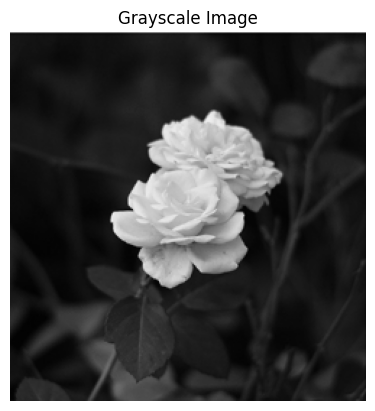

In [ ]:
# Activity 1: Reading and Displaying an Image

import cv2
import matplotlib.pyplot as plt
import numpy as np


image_path = "CV.png"
image = cv2.imread(image_path)
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

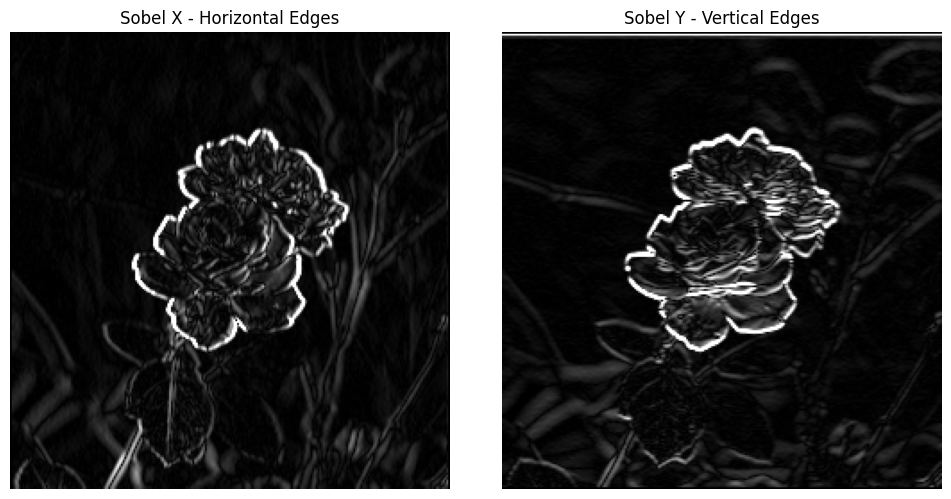

In [ ]:

# Activity 2: Computing the First Derivative Using Sobel Filter

# Compute first derivatives in X and Y directions
sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
# Convert negative gradient values to positive magnitudes
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)
# Display the Sobel derivatives
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(sobel_x_abs, cmap='gray')
plt.title('Sobel X - Horizontal Edges')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(sobel_y_abs, cmap='gray')
plt.title('Sobel Y - Vertical Edges')
plt.axis('off')
plt.tight_layout()
plt.show()

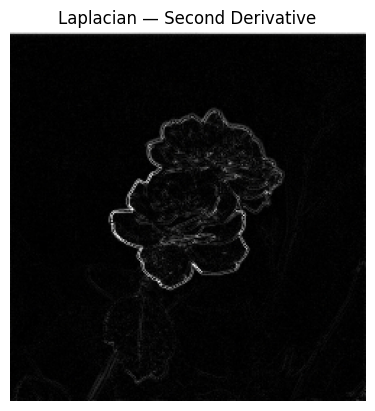

In [ ]:
# =========================
# Activity 3: Applying Second Derivative Using Laplacian Operator
# =========================
# Compute the Laplacian using the original grayscale image
laplacian = cv2.Laplacian(image, cv2.CV_64F)
# Convert the signed result to a displayable absolute image
laplacian_display = cv2.convertScaleAbs(laplacian)
plt.figure()
plt.imshow(laplacian_display, cmap="gray")
plt.title("Laplacian — Second Derivative")
plt.axis("off")
plt.show()

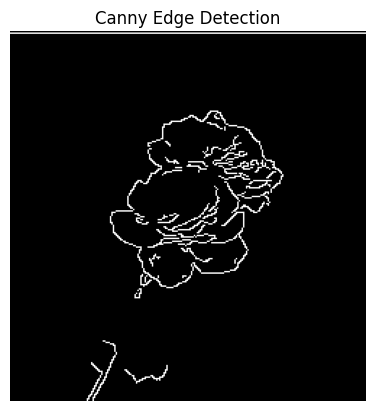

In [ ]:
# =========================
# Activity 4: Applying Canny Edge Detection
# =========================
canny_edges = cv2.Canny(image, 100, 200)
plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')
plt.show()

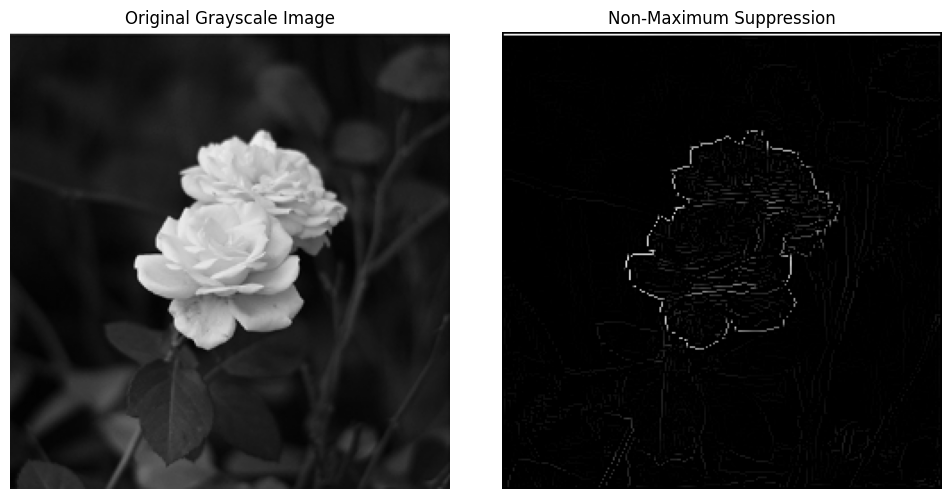

In [ ]:
# =========================
# Activity 5: Non-Maximum Suppression
# =========================

# Ensure the image is grayscale
if len(image.shape) == 3:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
else:
    gray = image.copy()

# Compute Sobel derivatives from the grayscale image
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Gradient magnitude
gradient_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

# Gradient direction
gradient_direction = np.arctan2(sobel_y, sobel_x)
gradient_direction = np.degrees(gradient_direction)

# Convert negative angles to 0–180 degrees
gradient_direction[gradient_direction < 0] += 180

# Create empty image for NMS
nms = np.zeros_like(gradient_magnitude)
rows, cols = gray.shape  # now guaranteed to be 2-D

# Non-Maximum Suppression
for i in range(1, rows - 1):
    for j in range(1, cols - 1):
        angle = gradient_direction[i, j]
        magnitude = gradient_magnitude[i, j]

        # 0 degrees
        if (angle < 22.5) or (angle >= 157.5):
            q = gradient_magnitude[i, j + 1]
            r = gradient_magnitude[i, j - 1]
        # 45 degrees
        elif angle < 67.5:
            q = gradient_magnitude[i - 1, j + 1]
            r = gradient_magnitude[i + 1, j - 1]
        # 90 degrees
        elif angle < 112.5:
            q = gradient_magnitude[i - 1, j]
            r = gradient_magnitude[i + 1, j]
        # 135 degrees
        else:
            q = gradient_magnitude[i - 1, j - 1]
            r = gradient_magnitude[i + 1, j + 1]

        # Keep only local maximum
        if magnitude >= q and magnitude >= r:
            nms[i, j] = magnitude

# Normalize for display
nms_display = cv2.normalize(nms, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Display result
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(nms_display, cmap="gray")
plt.title("Non-Maximum Suppression")
plt.axis("off")

plt.tight_layout()
plt.show()


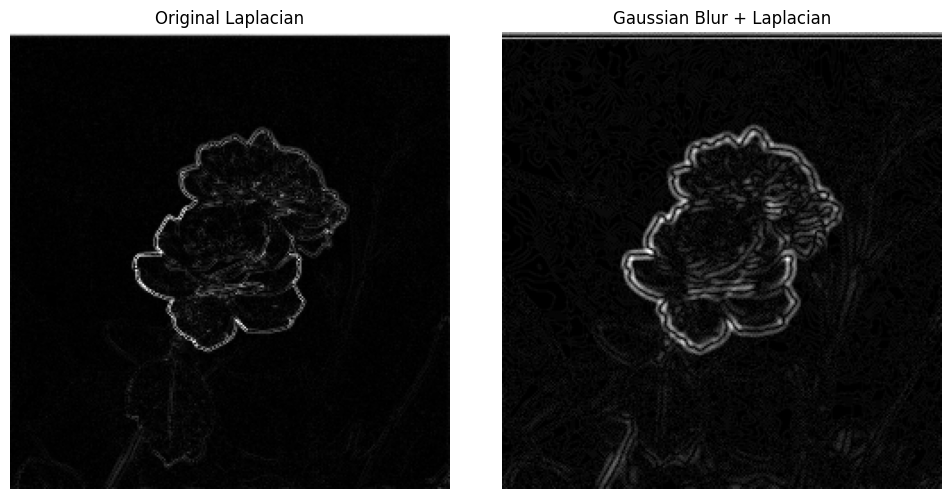

In [ ]:
#lab task 1:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the image in grayscale
# Replace 'your_image.jpg' with the path to your actual image file
image_path = 'CV.png'
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Compute Laplacian using the original grayscale image
laplacian = cv2.Laplacian(gray_image, cv2.CV_64F)

# Convert the signed result to a displayable image
laplacian_display = cv2.convertScaleAbs(laplacian)


# Apply Gaussian Blur first
blurred_image = cv2.GaussianBlur(gray_image, (5, 5), 1.5)

# Compute Laplacian after Gaussian Blur
laplacian_blurred = cv2.Laplacian(blurred_image, cv2.CV_64F)

# Convert the signed result to a displayable image
laplacian_blurred_display = cv2.convertScaleAbs(laplacian_blurred)


# Display both results side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(laplacian_display, cmap="gray")
plt.title("Original Laplacian")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(laplacian_blurred_display, cmap="gray")
plt.title("Gaussian Blur + Laplacian")
plt.axis("off")

plt.tight_layout()
plt.show()

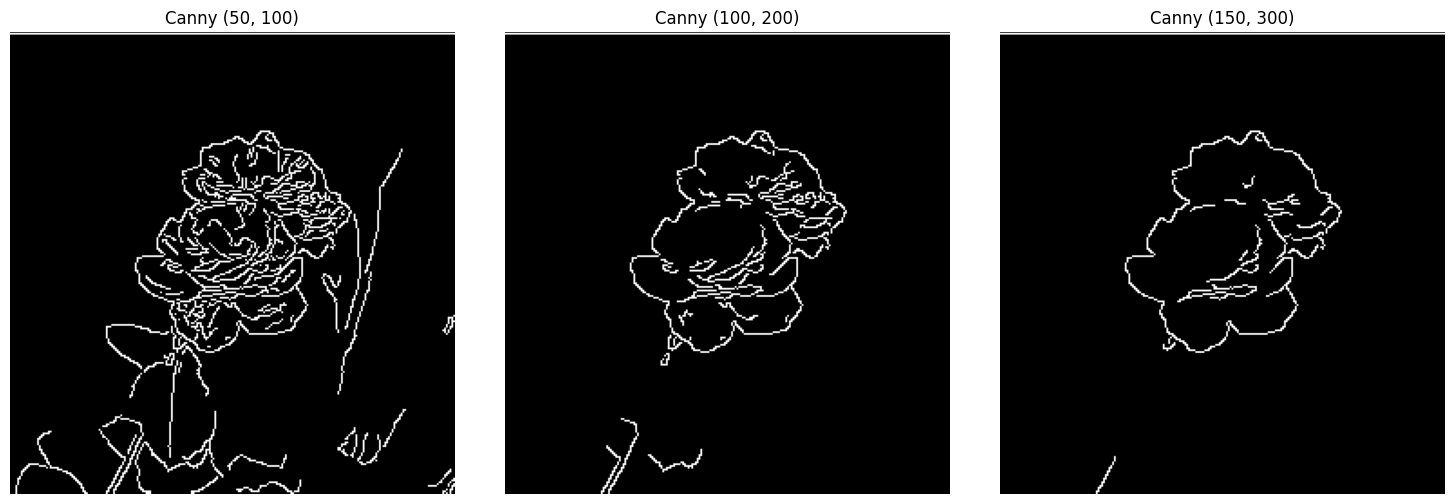

In [ ]:
# 1. Load the image in grayscale
image_path = 'CV.png'
img = cv2.imread(image_path, cv2.COLOR_BGR2GRAY)

# Canny with different threshold pairs
canny_50_100 = cv2.Canny(gray_image, 50, 100)
canny_100_200 = cv2.Canny(gray_image, 100, 200)
canny_150_300 = cv2.Canny(gray_image, 150, 300)


# Display all three edge maps
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(canny_50_100, cmap="gray")
plt.title("Canny (50, 100)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(canny_100_200, cmap="gray")
plt.title("Canny (100, 200)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(canny_150_300, cmap="gray")
plt.title("Canny (150, 300)")
plt.axis("off")

plt.tight_layout()
plt.show()